<a href="https://colab.research.google.com/github/Ahmedawadsaad/BlackWidow-Chess/blob/master/EuroSAT_Dataset_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [18]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [19]:
from pathlib import Path

drive_root = Path('/content/drive/MyDrive')

zip_files = sorted(
    p for p in drive_root.rglob('*')
    if p.is_file() and p.suffix.lower() == '.zip'
)

if not zip_files:
    print('not found My Drive.')
else:
    for number, path in enumerate(zip_files, start=1):
        print(f'{number}. {path.relative_to(drive_root)}')

1. DataScience_Project/EuroSAT_RGB.zip


In [20]:
from pathlib import Path
import zipfile

zip_path = Path(
    '/content/drive/MyDrive/DataScience_Project/EuroSAT_RGB.zip'
)

extract_dir = Path('/content/EuroSAT/raw')
extract_dir.mkdir(parents=True, exist_ok=True)

assert zip_path.exists(), 'ZIP file not found.'
assert zipfile.is_zipfile(zip_path), 'The file is not a valid ZIP archive.'

with zipfile.ZipFile(zip_path, 'r') as archive:
    root = extract_dir.resolve()

    for member in archive.infolist():
        target = (extract_dir / member.filename).resolve()

        if not target.is_relative_to(root):
            raise ValueError(
                f'Unsafe ZIP entry: {member.filename}'
            )

    archive.extractall(extract_dir)

print('Extraction completed.')
print('Image directory:', extract_dir)

Extraction completed.
Image directory: /content/EuroSAT/raw


In [22]:
from pathlib import Path
from collections import Counter
import pandas as pd

extract_dir = Path('/content/EuroSAT/raw')

extensions = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'}

image_paths = sorted(
    path for path in extract_dir.rglob('*')
    if path.is_file()
    and path.suffix.lower() in extensions
    and '__MACOSX' not in path.parts
    and not path.name.startswith('._')
)

assert image_paths, "We didn't find any images inside the folder."
class_counts = Counter(
    path.parent.name for path in image_paths
)

summary = pd.DataFrame(
    sorted(class_counts.items()),
    columns=['Class', 'Number of Images']
)

display(summary)

print('Total images:', len(image_paths))
print('Number of classes:', len(class_counts))
print('Image formats:', sorted({
    path.suffix.lower() for path in image_paths
}))

,Class,Number of Images
0,AnnualCrop,3000
1,Forest,3000
2,HerbaceousVegetation,3000
3,Highway,2500
4,Industrial,2500
5,Pasture,2000
6,PermanentCrop,2500
7,Residential,3000
8,River,2500
9,SeaLake,3000


Total images: 27000
Number of classes: 10
Image formats: ['.jpg']


In [23]:
from PIL import Image
from tqdm.auto import tqdm
import pandas as pd

records = []

for path in tqdm(image_paths, desc='Checking images'):
    record = {
        'relative_path': path.relative_to(extract_dir).as_posix(),
        'class': path.parent.name,
        'width': None,
        'height': None,
        'mode': None,
        'status': 'valid',
        'error': ''
    }

    try:
        with Image.open(path) as image:
            image.verify()

        with Image.open(path) as image:
            image.load()

            record['width'], record['height'] = image.size
            record['mode'] = image.mode

    except Exception as error:
        record['status'] = 'corrupt'
        record['error'] = str(error)

    records.append(record)

inventory = pd.DataFrame(records)

valid_images = inventory[
    inventory['status'] == 'valid'
].copy()

corrupt_images = inventory[
    inventory['status'] == 'corrupt'
].copy()

print('Readable images:', len(valid_images))
print('Corrupt images:', len(corrupt_images))

print('\nImage dimensions:')
display(
    valid_images.groupby(['width', 'height'])
    .size()
    .reset_index(name='Number of Images')
)

print('\nColor modes:')
display(
    valid_images.groupby('mode')
    .size()
    .reset_index(name='Number of Images')
)

if not corrupt_images.empty:
    print('\nFiles requiring review:')
    display(corrupt_images[['relative_path', 'error']])

Checking images:   0%|          | 0/27000 [00:00<?, ?it/s]

Readable images: 27000
Corrupt images: 0

Image dimensions:


,width,height,Number of Images
0,64,64,27000



Color modes:


,mode,Number of Images
0,RGB,27000


In [24]:
import hashlib
from PIL import Image
from tqdm.auto import tqdm

hashes = []

for relative_path in tqdm(
    valid_images['relative_path'],
    desc='Checking duplicates'
):
    path = extract_dir / relative_path

    with Image.open(path) as image:
        rgb = image.convert('RGB')

        digest = hashlib.sha256()
        digest.update(str(rgb.size).encode())
        digest.update(rgb.tobytes())

        hashes.append(digest.hexdigest())

valid_images['pixel_hash'] = hashes

duplicate_images = valid_images[
    valid_images.duplicated('pixel_hash', keep=False)
].copy()

duplicate_groups = duplicate_images['pixel_hash'].nunique()

extra_copies = valid_images.duplicated(
    'pixel_hash', keep='first'
).sum()

classes_per_hash = valid_images.groupby(
    'pixel_hash'
)['class'].nunique()

conflicting_hashes = classes_per_hash[
    classes_per_hash > 1
].index

label_conflicts = valid_images[
    valid_images['pixel_hash'].isin(conflicting_hashes)
].copy()

print('Duplicate groups:', duplicate_groups)
print('Images involved in duplicates:', len(duplicate_images))
print('Extra duplicate copies:', int(extra_copies))
print('Groups with conflicting labels:', len(conflicting_hashes))

if not duplicate_images.empty:
    print('\nDuplicate examples:')
    display(
        duplicate_images.sort_values('pixel_hash')[
            ['relative_path', 'class', 'pixel_hash']
        ].head(20)
    )

if not label_conflicts.empty:
    print('\nImages with conflicting labels:')
    display(
        label_conflicts.sort_values('pixel_hash')[
            ['relative_path', 'class']
        ]
    )

Checking duplicates:   0%|          | 0/27000 [00:00<?, ?it/s]

Duplicate groups: 0
Images involved in duplicates: 0
Extra duplicate copies: 0
Groups with conflicting labels: 0


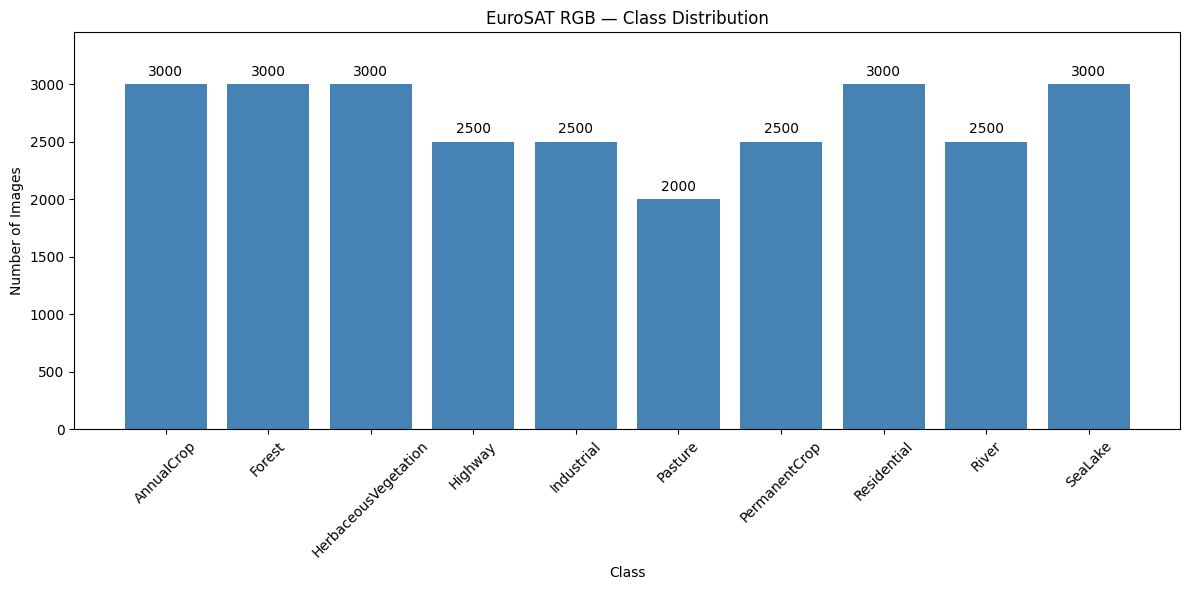

In [25]:
import matplotlib.pyplot as plt
from pathlib import Path

results_dir = Path('/content/EuroSAT/results')
results_dir.mkdir(parents=True, exist_ok=True)

class_counts = (
    valid_images.groupby('class')
    .size()
    .sort_index()
)

fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.bar(
    class_counts.index,
    class_counts.values,
    color='steelblue'
)

ax.bar_label(bars, padding=4)

ax.set_title('EuroSAT RGB — Class Distribution')
ax.set_xlabel('Class')
ax.set_ylabel('Number of Images')
ax.tick_params(axis='x', rotation=45)
ax.set_ylim(0, class_counts.max() * 1.15)

fig.tight_layout()

fig.savefig(
    results_dir / 'class_distribution.png',
    dpi=200,
    bbox_inches='tight'
)

plt.show()

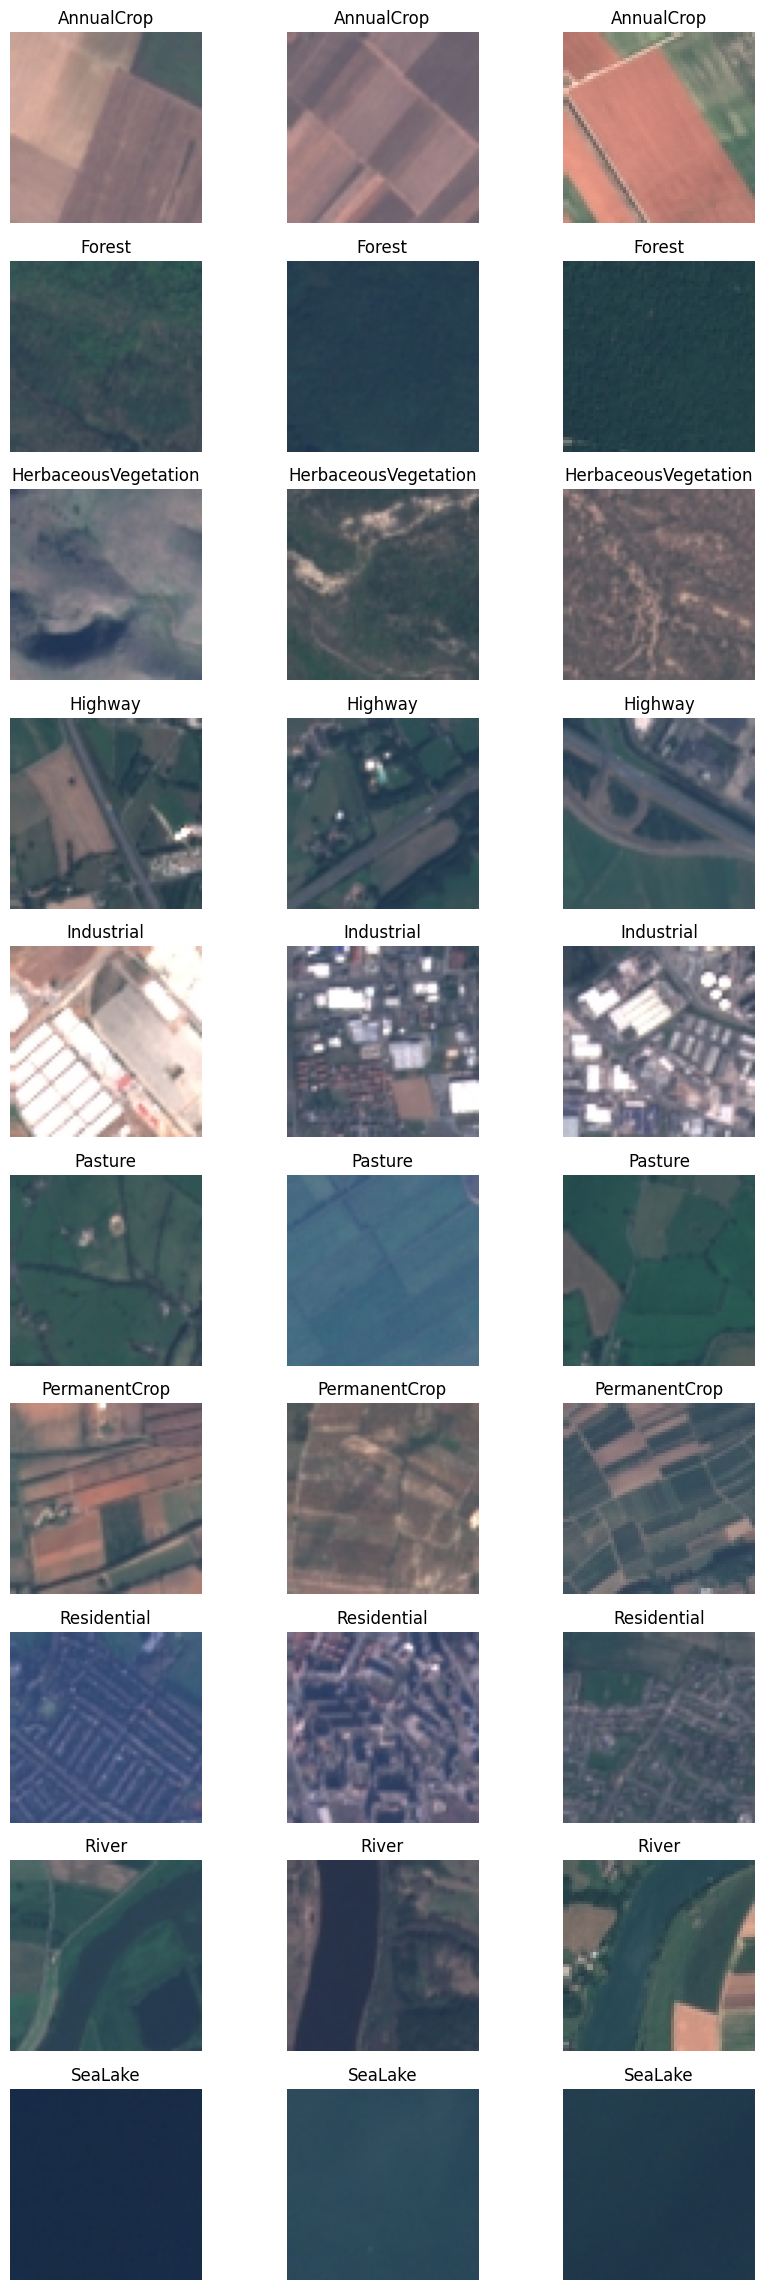

In [26]:
import random
from PIL import Image

rng = random.Random(42)
classes = sorted(valid_images['class'].unique())

fig, axes = plt.subplots(
    nrows=len(classes),
    ncols=3,
    figsize=(9, 2.3 * len(classes)),
    squeeze=False
)

for row, class_name in enumerate(classes):

    class_paths = valid_images.loc[
        valid_images['class'] == class_name,
        'relative_path'
    ].tolist()

    selected_paths = rng.sample(class_paths, 3)

    for column, relative_path in enumerate(selected_paths):

        with Image.open(extract_dir / relative_path) as image:
            axes[row, column].imshow(image.convert('RGB'))

        axes[row, column].set_title(class_name)
        axes[row, column].axis('off')

fig.tight_layout()

fig.savefig(
    results_dir / 'class_samples.png',
    dpi=200,
    bbox_inches='tight'
)

plt.show()

In [27]:
import json

valid_images.to_csv(
    results_dir / 'image_inventory.csv',
    index=False
)

corrupt_images.to_csv(
    results_dir / 'corrupt_images.csv',
    index=False
)

duplicate_images.to_csv(
    results_dir / 'duplicate_images.csv',
    index=False
)

label_conflicts.to_csv(
    results_dir / 'label_conflicts.csv',
    index=False
)

class_counts.rename('image_count').to_csv(
    results_dir / 'class_counts.csv'
)

report = {
    'dataset': 'EuroSAT RGB',
    'objective': 'Land use and land cover image classification',
    'total_images': int(len(inventory)),
    'readable_images': int(len(valid_images)),
    'number_of_classes': int(valid_images['class'].nunique()),
    'image_dimensions': [
        [int(w), int(h)]
        for w, h in valid_images[
            ['width', 'height']
        ].drop_duplicates().itertuples(index=False, name=None)
    ],
    'color_modes': valid_images['mode'].unique().tolist(),
    'corrupt_images': int(len(corrupt_images)),
    'exact_duplicate_groups': int(duplicate_groups),
    'extra_duplicate_copies': int(extra_copies),
    'conflicting_label_groups': int(len(conflicting_hashes)),
    'class_counts': {
        name: int(count)
        for name, count in class_counts.items()
    },
    'largest_to_smallest_class_ratio': float(
        class_counts.max() / class_counts.min()
    ),
    'limitations': [
        'Near-duplicate images were not checked.',
        'Geographic overlap was not checked.',
        'Labels were inferred from parent folder names.',
        'Sample inspection does not verify every label.'
    ]
}

with open(
    results_dir / 'dataset_summary.json',
    'w',
    encoding='utf-8'
) as file:
    json.dump(report, file, indent=2)

print('Reports saved ✅')

for path in sorted(results_dir.iterdir()):
    print(path.name)

Reports saved ✅
class_counts.csv
class_distribution.png
class_samples.png
corrupt_images.csv
dataset_summary.json
duplicate_images.csv
image_inventory.csv
label_conflicts.csv


In [28]:
import shutil
from pathlib import Path

save_dir = Path(
    '/content/drive/MyDrive/DataScience_Project/Task1_Results'
)
save_dir.mkdir(parents=True, exist_ok=True)

for path in results_dir.iterdir():
    if path.is_file():
        shutil.copy2(path, save_dir / path.name)

print('Results saved to Google Drive ✅')

for path in sorted(save_dir.iterdir()):
    print(path.name)

Results saved to Google Drive ✅
class_counts.csv
class_distribution.png
class_samples.png
corrupt_images.csv
dataset_summary.json
duplicate_images.csv
image_inventory.csv
label_conflicts.csv
